# 06 - Unsupervised learning: what kinds of stations are there?

**Who worked on this:** Mohammed AbuQamar

**Question:** the model treats the 100 stations as 100 unrelated labels. Do they fall into a few *types* with a similar daily rhythm (for example commuter stations versus leisure stations)? If so, that is something we can **see**, **explain**, and hand to the model as an extra feature.

**Method (Unsupervised learning chapter):** KMeans clustering. There is no target here: we do not tell the model who is a commuter station, it finds groups of stations that sit close together in a multi-dimensional space. Each station becomes one point with 48 coordinates: its share of daily demand in each of the 24 hours, separately for weekdays and weekends.

**Steps:** build profiles -> **scale** them -> choose the number of clusters with the **inertia (elbow) plot** -> fit -> interpret -> save the mapping for the model.

**Leakage rule:** profiles are computed from **training rows only**. If test-period behaviour shaped the clusters, the cluster feature would quietly carry information about the future.

In [1]:
import sys
sys.path.append(".")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from src.features import (load_demand, time_split, split_dates, station_profiles,
                          fit_station_clusters, CLUSTER_PATH, TARGET)
sns.set_theme(style="whitegrid")

df = load_demand()
train, valid, test = time_split(df)
print(f"profiles are built from {len(train):,} training rows ({train.ts.min():%Y-%m} -> {train.ts.max():%Y-%m})")

profiles are built from 6,925,801 training rows (2013-06 -> 2024-09)


## 1. Station profiles
Each row is divided by its own total, so we compare the **shape** of the day, not the size of the station. A busy station and a quiet one with the same rhythm should land in the same cluster. Size can be looked at afterwards (section 5).

Stations with less than 30 days of history in the training period (very new stations) get no profile; the model will mark them `-1`.

In [2]:
profiles = station_profiles(train)
print(profiles.shape, "->", profiles.shape[0], "stations x", profiles.shape[1], "coordinates (24 weekday hours + 24 weekend hours)")
missing = sorted(set(df["station"].astype(str).unique()) - set(profiles.index))
print(f"{len(missing)} stations without a profile (too new):", missing[:5])
profiles.iloc[:3, :6]

(98, 48) -> 98 stations x 48 coordinates (24 weekday hours + 24 weekend hours)
2 stations without a profile (too new): ['Kent Ave & N 3 St', 'Park Ave & E 42 St']


,wd_00,wd_01,wd_02,wd_03,wd_04,wd_05
station,,,,,,
1 Ave & E 18 St,0.004011,0.001705,0.000896,0.000580,0.001083,0.006089
1 Ave & E 38 St,0.004502,0.001979,0.000824,0.000627,0.000594,0.004122
1 Ave & E 62 St,0.004404,0.002492,0.002027,0.001090,0.002548,0.006139


## 2. Scaling
KMeans groups points by *distance*, and one distance is used for all 48 coordinates. If one coordinate has a much larger range than the others it decides the clusters on its own (Scaling slides: the same data is easy to cluster in one plot and hard in the other). We standardise every column to mean 0 and spread 1.

*Side effect to be aware of:* after scaling, quiet night hours count as much as the rush-hour peaks. That is fine for finding rhythm types, but it can make small night-time differences look important.

In [3]:
scaled = StandardScaler().fit_transform(profiles)
print("mean ~", scaled.mean().round(3), "| std ~", scaled.std().round(3))

mean ~ -0.0 | std ~ 1.0


## 3. How many clusters? Inertia plot
*Inertia* is the total squared distance of the stations to the centre of their cluster. It always goes down when you add clusters, so we look for the **elbow**: the point after which adding clusters gains little. As a second opinion we also show the *silhouette score* (from -1 to 1; higher means the clusters are better separated from each other).

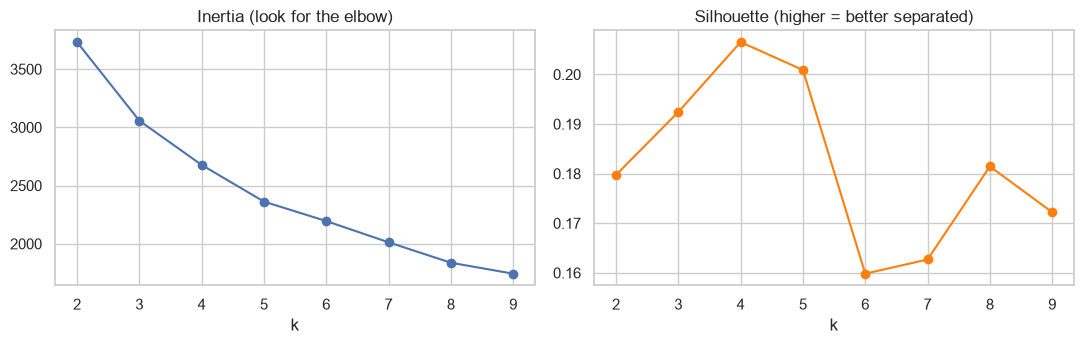

 k  inertia  silhouette
 2   3732.7       0.180
 3   3057.4       0.192
 4   2677.1       0.207
 5   2362.1       0.201
 6   2194.9       0.160
 7   2012.6       0.163
 8   1837.0       0.181
 9   1742.9       0.172


In [4]:
from sklearn.cluster import KMeans
ks = range(2, min(10, len(profiles) - 1))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(scaled)
    inertia.append(km.inertia_); sil.append(silhouette_score(scaled, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set_title("Inertia (look for the elbow)"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sil, "o-", color="tab:orange"); ax[1].set_title("Silhouette (higher = better separated)"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 3)}).to_string(index=False))

**Choose k.** Read the elbow plot and the silhouette plot and set `K` below. If you leave it as `None`, the code takes the k with the best silhouette score. Between two similar choices prefer the **smaller** k: fewer groups are easier to explain and to defend.

In [5]:
K = None                                     # e.g. K = 4 after reading the plots
if K is None:
    K = list(ks)[int(np.argmax(sil))]
print("K =", K)

clusters, (scaler, km) = fit_station_clusters(profiles, K)
clusters.value_counts().sort_index().to_frame("stations")

K = 4


,stations
cluster,
0,22
1,28
2,13
3,35


## 4. What are the clusters? The average daily rhythm of each
This is the *interpretation* step, the reason to do unsupervised learning at all. A cluster number means nothing until we look at what its stations have in common.

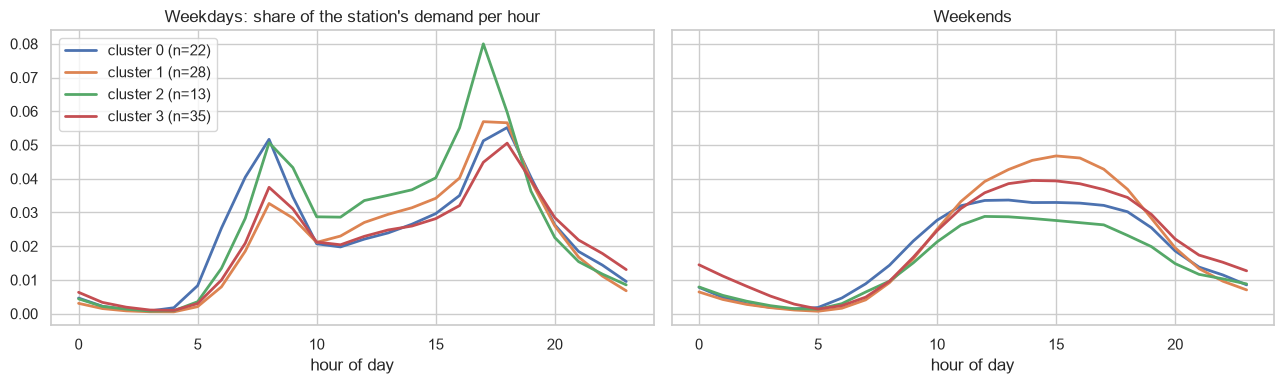

In [6]:
hours = range(24)
wd = profiles[[f"wd_{h:02d}" for h in hours]]; we = profiles[[f"we_{h:02d}" for h in hours]]
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for c in range(K):
    members = clusters[clusters == c].index
    ax[0].plot(hours, wd.loc[members].mean(), label=f"cluster {c} (n={len(members)})", lw=2)
    ax[1].plot(hours, we.loc[members].mean(), lw=2)
ax[0].set_title("Weekdays: share of the station's demand per hour"); ax[1].set_title("Weekends")
for a in ax: a.set_xlabel("hour of day")
ax[0].legend(); plt.tight_layout(); plt.show()

In [7]:
# the same picture in numbers, so every cluster can be described in one line
rows = []
for c in range(K):
    m = clusters[clusters == c].index
    w, e = wd.loc[m].mean(), we.loc[m].mean()
    rows.append({"cluster": c, "stations": len(m),
                 "weekday peak hour": int(w.values.argmax()),
                 "weekend peak hour": int(e.values.argmax()),
                 "% weekday trips 7-9h": round(100 * w.iloc[7:10].sum() / (w.sum() + e.sum()) * 2, 1),
                 "% weekday trips 16-19h": round(100 * w.iloc[16:20].sum() / (w.sum() + e.sum()) * 2, 1),
                 "weekend share of demand %": round(100 * e.sum() / (w.sum() + e.sum()), 1)})
summary = pd.DataFrame(rows).set_index("cluster")
size = train[train.ts >= train.ts.max() - pd.Timedelta(days=365)].groupby("station", observed=True)[TARGET].mean()
summary["avg trips per hour (last train year)"] = [round(size.reindex(clusters[clusters == c].index).mean(), 1) for c in range(K)]
summary

,stations,weekday peak hour,weekend peak hour,% weekday trips 7-9h,% weekday trips 16-19h,weekend share of demand %,avg trips per hour (last train year)
cluster,,,,,,,
0,22,18,13,25.3,36.4,43.6,9.5
1,28,17,15,15.9,38.6,48.4,10.7
2,13,17,12,24.4,46.2,35.9,8.6
3,35,18,14,17.9,33.4,49.2,8.6


**Where are they?** If the clusters mean something real, they should show up on the map, for example commuter stations around the big stations and business districts, leisure stations at parks and the waterfront.

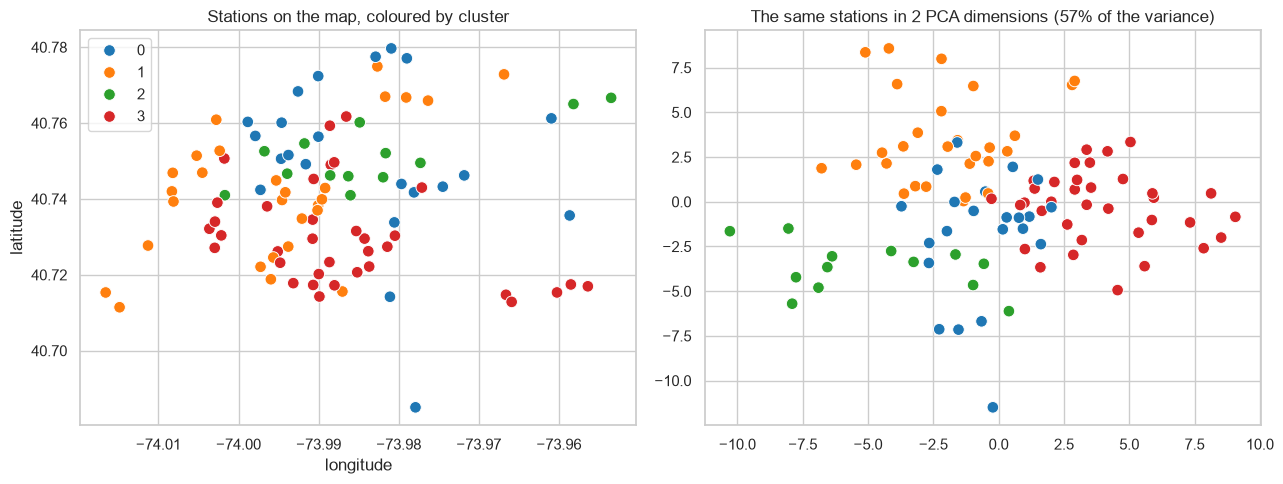

In [8]:
coords = df.drop_duplicates("station").set_index(df.drop_duplicates("station")["station"].astype(str))[["lat", "lng"]]
coords = coords.reindex(clusters.index)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=coords.lng, y=coords.lat, hue=clusters.values, palette="tab10", s=70, ax=ax[0])
ax[0].set_title("Stations on the map, coloured by cluster"); ax[0].set_xlabel("longitude"); ax[0].set_ylabel("latitude")
# the 48-dimensional space squashed to 2 dimensions (PCA), to see how separated the groups are
pc = PCA(n_components=2).fit(scaled)
xy = pc.transform(scaled)
sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=clusters.values, palette="tab10", s=70, ax=ax[1], legend=False)
ax[1].set_title(f"The same stations in 2 PCA dimensions ({pc.explained_variance_ratio_.sum():.0%} of the variance)")
plt.tight_layout(); plt.show()

**Write your findings here (after running):** give each cluster a name based on the table (for example "commuter", "leisure / weekend", "all day"). Are clusters grouped on the map? Is something surprising, such as stations that look like commuter stations but sit far from the centre?

## 5. Save the mapping
`models/station_clusters.csv` maps each station to its cluster. The next notebook adds it as a feature (`cluster`) and checks with a controlled experiment whether it improves the validation score. The API will use the same file, because the user picks a station and the model needs its cluster.

In [9]:
Path("models").mkdir(exist_ok=True)
out = clusters.rename_axis("station").reset_index()
out["k"] = K
out.to_csv(CLUSTER_PATH, index=False)
print(f"saved {len(out)} stations to {CLUSTER_PATH}")
out.head()

saved 98 stations to models\station_clusters.csv


,station,cluster,k
0,1 Ave & E 18 St,0,4
1,1 Ave & E 38 St,0,4
2,1 Ave & E 62 St,0,4
3,1 Ave & E 68 St,2,4
4,10 Ave & W 14 St,1,4


**Limits to mention in the presentation:**
- Clusters come from the **training period**. A station that changes character later (new bike lanes, a neighbourhood changing) keeps its old cluster until the retraining pipeline recomputes it.
- KMeans always returns k groups, even if the data has no real groups. The silhouette score and the map are our checks that these are meaningful.
- Whether the clusters help *prediction* is not decided here. The experiment in the next notebook decides that.